# Model characteristics
- Module validity verification
- Robustness investigation

In [ ]:
import json
import torch
import numpy as np
from tqdm.notebook import tqdm
import matplotlib.pyplot as plt
from typing import Dict, Optional, Tuple, Union

from utils.metrics import PIVmetric
from utils.visualizer import plot_flow_field
from matplotlib.ticker import MultipleLocator

# 数据加载：事件、光流
from generator.flow import FlowManager
from generator.images import config_events
from generator.loader import EventManager


from utils.add_noise import add_event_noise
from utils.painter import extract_data, plot_curvegraph, plot_loss_curves, analyze_error, plot_module_validity

# from methods import compute_flow_quantities
from methods.affinegs.gaussian_flow.config import GaussianFlowConfig
from methods.affinegs.gaussian_flow.training import run_gaussian_flow

seed = 42
np.random.seed(seed)
torch.manual_seed(seed)              
torch.cuda.manual_seed(seed)         
torch.cuda.manual_seed_all(seed)   

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)


In [2]:
def save_results_to_json(results, save_path, indent=1):
    def convert_numpy_types(obj):
        if isinstance(obj, (np.integer, np.floating)): 
            return obj.item()
        elif isinstance(obj, np.ndarray): 
            return obj.tolist()
        return obj
    
    try:
        with open(save_path, 'w', encoding='utf-8') as f:
            json.dump(results, f, ensure_ascii=False, indent=indent, default=convert_numpy_types)
        print(f"✅ Results saved to: {save_path}")
    except Exception as e:
        print(f"❌ Save failed: {e}")

In [3]:
flow0 = FlowManager(mode="data", data_path="./data/datasets/JHTDB_isotropic1024_hd_00001_flow.npz")
flow1 = FlowManager(mode="data", data_path="./data/datasets/DNS_turbulence_00001_flow.npz")
flow2 = FlowManager(mode="data", data_path="./data/datasets/SQG_00001_flow.npz")

flow_funcs = [flow0, flow1, flow2]
flow_names = ["JHTDB-isotropic", "DNS-turbulence", "SQG"]

## Module validity verification

- Same Gaussian quantity

In [ ]:
jacobian_results = {}

for flow_index in tqdm(range(3), desc="Flows", position=0):

    flow_name = f"flow{flow_index}"
    jacobian_results[flow_name] = {}

    # ================= 数据生成 =================
    flow_func = globals()[flow_name].evaluate

    cfg_evts = config_events()
    cfg_evts.time_length = 5
    cfg_evts.d = 0.5
    cfg_evts.density = 0.05
    
    event_loader = EventManager(source_type="simulator", path=None, cfg=cfg_evts, flow_func=flow_func)

    evts, (u, v) = event_loader.load()
    flowgt = torch.stack([u, v], dim=0).to(device)
    
    events = evts[(evts[:, 2] > 0) & (evts[:, 2] < 3)]
    h_gt = u.cpu().numpy()
    w_gt = v.cpu().numpy()

    configs = [
        (enable_jacobian, init_n)
        for enable_jacobian in [1, 0]
        for init_n in range(50, 510, 50)
    ]

    for enable_jacobian, init_n in tqdm(configs, desc=f"{flow_name}", leave=False, position=1):

        jac_key = str(enable_jacobian)
        if jac_key not in jacobian_results[flow_name]:
            jacobian_results[flow_name][jac_key] = {}

        rmse_list = []
        aee_list = []

        # ===== repeat 10 times =====
        for _ in tqdm(range(10), desc="repeat", leave=False, position=2):

            cfg = GaussianFlowConfig(verbose=False, init_n=init_n, enable_jacobian=enable_jacobian, phase=[500, 200, 250], iterations=300, lr_j=0.001)

            res = run_gaussian_flow(events=events, cfg=cfg, flowgt=None)

            pred_h, pred_w = res.flow[0], res.flow[1]
            rmse, aee = PIVmetric(pred_h, pred_w, h_gt, w_gt, show=False)[:2]

            rmse_list.append(rmse)
            aee_list.append(aee)

        rmse_mean = round(float(np.mean(sorted(rmse_list)[1:-1])), 4)
        aee_mean = round(float(np.mean(sorted(aee_list)[1:-1])), 4)

        jacobian_results[flow_name][jac_key][str(init_n)] = {"rmse": rmse_mean, "aee": aee_mean}
save_results_to_json(jacobian_results, "./output/EXP1/1-jacobian-results.json", indent=1)

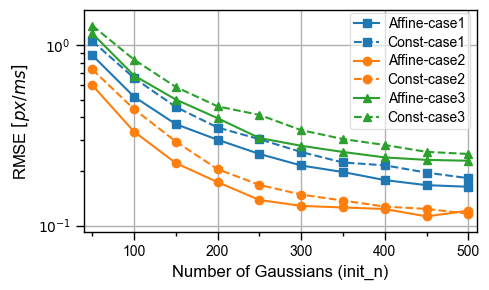

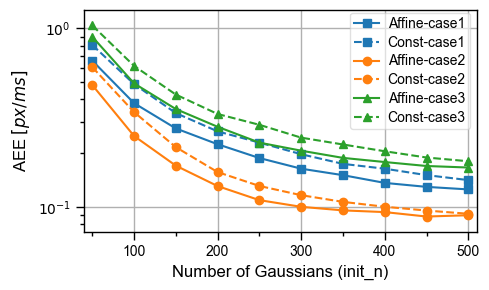

In [4]:
import importlib
import utils.painter as painter
importlib.reload(painter)
plot_module_validity = painter.plot_module_validity

with open("./output/EXP1/1-jacobian-results.json", 'r', encoding='utf-8') as f:
    jacobian_data = json.load(f)

jacobian_x_major_ticks = list(range(100, 501, 100))
jacobian_x_minor_ticks = list(range(50, 501, 50))

for metric in ["rmse", "aee"]:
    plot_module_validity(
        jacobian_data,
        flow_names=flow_names,
        metric=metric,
        save_path=f"./output/EXP1/1-jacobian-{metric}.pdf",
        x_label="Number of Gaussians (init_n)",
        style_names={"1": "Affine", "0": "Const"},
        style_linestyles={"1": "-", "0": "--"},
        style_legend_anchor=(0.58, 1.02),
        figsize=(5, 3),
        xlim=(40, 510),
        x_major_ticks=jacobian_x_major_ticks,
        x_minor_ticks=jacobian_x_minor_ticks,
        ticks_size=10,
        legend_size=10,
        label_size=12,
        legend_mode="combined",
        combined_legend_loc="upper right",
        combined_legend_anchor=(1.0, 1.02),
        combined_legend_ncol=1,
        combined_legend_label_mode="method_case",
    )

- Same Gaussian quantity with frozen geometry


In [ ]:
from methods.affinegs.cmax import ContrastMaximizationLoss
from methods.affinegs.gaussian_flow.model import GaussianVelocityField_Tiled
from methods.affinegs.gaussian_flow.training import train_gaussian_flow, render_gaussian_flow
from methods.affinegs.gaussian_flow.utils import divergence_regularizer


def clone_shared_geometry_model(base_model, enable_jacobian, cfg):
    """Create a model with exactly the same Gaussian geometry as base_model."""
    model = GaussianVelocityField_Tiled(
        num_gaussians=base_model.num_gaussians,
        H=base_model.H,
        W=base_model.W,
        tile_size=base_model.tile_size,
        enable_jacobian=enable_jacobian,
        device=base_model.mu.device,
        jacobian_mode=cfg.jacobian_mode,
        init_scale_h=cfg.init_scale_h,
        init_scale_w=cfg.init_scale_w,
    ).to(base_model.mu.device)

    with torch.no_grad():
        model.mu.copy_(base_model.mu)
        model.log_scale.copy_(base_model.log_scale)
        model.rotation.copy_(base_model.rotation)
        model.opacity_logit.copy_(base_model.opacity_logit)
        model.local_velocity.copy_(base_model.local_velocity)
        if model.J_params is not None:
            model.J_params.zero_()

    # Freeze only the Gaussian support. The ablation tests the velocity model on identical geometry.
    for param in (model.mu, model.log_scale, model.rotation, model.opacity_logit):
        param.requires_grad_(False)

    model.rebuild_indexer()
    return model


def train_frozen_geometry_model(model, events, cfg, iterations):
    model.train()
    events = events.to(model.mu.device)

    param_groups = [
        {"params": [model.local_velocity], "lr": 0.05, "name": "velocity"},
    ]
    if model.J_params is not None:
        lr_j = cfg.lr_j if cfg.lr_j is not None else 0.001
        param_groups.append({"params": [model.J_params], "lr": lr_j, "name": "jacobian"})

    optimizer = torch.optim.Adam(param_groups, betas=(0.9, 0.999), eps=1e-15)
    cmax_loss_fn = ContrastMaximizationLoss(
        loss_type=cfg.cmax_loss_type,
        sigma=cfg.cmax_sigma,
        kernel_size=cfg.cmax_kernel_size,
    ).to(model.mu.device)

    for i in range(iterations):
        optimizer.zero_grad(set_to_none=True)
        pred_flow, _, _, _ = model(rebuild_index=(i == 0), compute_derivatives=False)
        loss_data = cmax_loss_fn(events, pred_flow, (cfg.H, cfg.W))
        div_loss = divergence_regularizer(pred_flow, top_ratio=cfg.div_top_ratio)
        weight_div = cfg.w_div if i < cfg.div_last else 0.0
        loss = loss_data + weight_div * div_loss
        loss.backward()
        optimizer.step()

    return model


frozen_geometry_results = {}
frozen_init_ns = list(range(50, 510, 50))
frozen_repeats = 10
frozen_pretrain_iterations = 300
frozen_refine_iterations = 150

for flow_index in tqdm(range(3), desc="Flows", position=0):
    flow_name = f"flow{flow_index}"
    frozen_geometry_results[flow_name] = {"1": {}, "0": {}}

    flow_func = globals()[flow_name].evaluate

    cfg_evts = config_events()
    cfg_evts.time_length = 5
    cfg_evts.d = 0.5
    cfg_evts.density = 0.05

    event_loader = EventManager(source_type="simulator", path=None, cfg=cfg_evts, flow_func=flow_func)
    evts, (u, v) = event_loader.load()
    events = evts[(evts[:, 2] > 0) & (evts[:, 2] < 3)]

    h_gt = u.cpu().numpy()
    w_gt = v.cpu().numpy()

    for init_n in tqdm(frozen_init_ns, desc=f"{flow_name}", leave=False, position=1):
        metric_cache = {
            "1": {"rmse": [], "aee": []},
            "0": {"rmse": [], "aee": []},
        }

        for _ in tqdm(range(frozen_repeats), desc="repeat", leave=False, position=2):
            base_cfg = GaussianFlowConfig(
                verbose=False,
                init_n=init_n,
                enable_jacobian=False,
                phase=[10**9, 10**9, 10**9],
                iterations=frozen_pretrain_iterations,
                lr_j=0.001,
            )
            base_model, _ = train_gaussian_flow(events=events, cfg=base_cfg, flowgt=None)

            for jac_key, enable_jacobian in [("1", True), ("0", False)]:
                refine_cfg = GaussianFlowConfig(
                    verbose=False,
                    init_n=init_n,
                    enable_jacobian=enable_jacobian,
                    phase=[10**9, 10**9, 10**9],
                    iterations=frozen_refine_iterations,
                    lr_j=0.001,
                )
                model = clone_shared_geometry_model(base_model, enable_jacobian, refine_cfg)
                model = train_frozen_geometry_model(model, events, refine_cfg, frozen_refine_iterations)
                res = render_gaussian_flow(model, verbose=False)

                pred_h, pred_w = res.flow[0], res.flow[1]
                rmse, aee = PIVmetric(pred_h, pred_w, h_gt, w_gt, show=False)[:2]
                metric_cache[jac_key]["rmse"].append(rmse)
                metric_cache[jac_key]["aee"].append(aee)

                del model, res
                torch.cuda.empty_cache()

            del base_model
            torch.cuda.empty_cache()

        for jac_key in ["1", "0"]:
            rmse_vals = sorted(metric_cache[jac_key]["rmse"])
            aee_vals = sorted(metric_cache[jac_key]["aee"])
            if len(rmse_vals) > 2:
                rmse_vals = rmse_vals[1:-1]
                aee_vals = aee_vals[1:-1]

            frozen_geometry_results[flow_name][jac_key][str(init_n)] = {
                "rmse": round(float(np.mean(rmse_vals)), 4),
                "aee": round(float(np.mean(aee_vals)), 4),
                "init_n": int(init_n),
                "frozen_geometry": True,
                "pretrain_iterations": int(frozen_pretrain_iterations),
                "refine_iterations": int(frozen_refine_iterations),
                "repeats": int(frozen_repeats),
            }

save_results_to_json(frozen_geometry_results, "./output/EXP1/2-jacobian-frozen-geometry-results.json", indent=1)

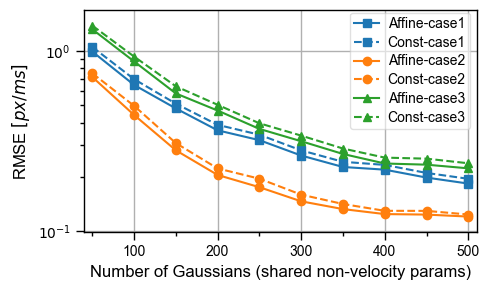

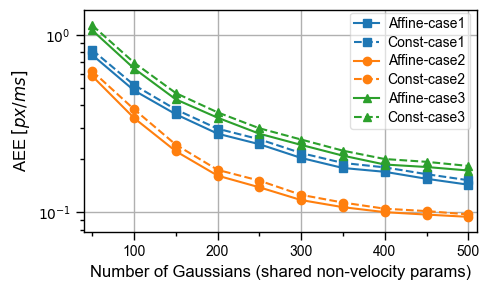

In [6]:
import importlib
import utils.painter as painter
importlib.reload(painter)
plot_module_validity = painter.plot_module_validity

with open("./output/EXP1/2-jacobian-frozen-geometry-results.json", 'r', encoding='utf-8') as f:
    frozen_geometry_data = json.load(f)

jacobian_x_major_ticks = list(range(100, 501, 100))
jacobian_x_minor_ticks = list(range(50, 501, 50))

for metric in ["rmse", "aee"]:
    plot_module_validity(
        frozen_geometry_data,
        flow_names=flow_names,
        metric=metric,
        save_path=f"./output/EXP1/2-jacobian-frozen-geometry-{metric}.pdf",
        x_label="Number of Gaussians (shared non-velocity params)",
        style_names={"1": "Affine", "0": "Const"},
        style_linestyles={"1": "-", "0": "--"},
        style_legend_anchor=(0.58, 1.02),
        figsize=(5, 3),
        xlim=(40, 510),
        x_major_ticks=jacobian_x_major_ticks,
        x_minor_ticks=jacobian_x_minor_ticks,
        ticks_size=10,
        legend_size=10,
        label_size=12,
        legend_mode="combined",
        combined_legend_loc="upper right",
        combined_legend_anchor=(1.0, 1.02),
        combined_legend_ncol=1,
        combined_legend_label_mode="method_case",
    )

## Robustness investigation

- particle density

In [ ]:
density_results = {}

for i in tqdm(range(3), desc="methods"):
    flow_func = globals()[f"flow{i}"].evaluate
    cfg_evts = config_events()
    cfg_evts.time_length = 4
    cfg_evts.d = 0.05

    single_flow_results = {}
    density_values = np.round(np.arange(0.01, 0.1001, 0.01), 2)

    for density in tqdm(density_values, desc=f"{flow_names[i]}-Density", leave=False):
        single_density_rmse = []
        single_density_aee = []
        
        for _ in range(10):
            cfg_evts.density = density
    
            event_loader = EventManager(source_type="simulator", path=None, cfg=cfg_evts, flow_func=flow_func)
            evts, (u, v) = event_loader.load()

            u_gt, v_gt = u.cpu().numpy(), v.cpu().numpy()

            events = evts[(evts[:, 2] > 0) & (evts[:, 2] < 3)]
            cfg = GaussianFlowConfig(lr_j=0.001)
            result = run_gaussian_flow(events=events, cfg=cfg, flowgt=None)
            
            pred_h, pred_w = result.flow[0], result.flow[1]
            res = PIVmetric(u_gt, v_gt, pred_h, pred_w, show=False)
            rmse, aee = res[0], res[1]
            single_density_rmse.append(rmse)
            single_density_aee.append(aee)

        rmse_mean = np.mean(np.sort(single_density_rmse)[1:-1])
        aee_mean = np.mean(np.sort(single_density_aee)[1:-1])

        single_flow_results[f"{density:.6f}"] = {
            "rmse": round(float(rmse_mean), 4),
            "aee": round(float(aee_mean), 4)}

    density_results[flow_names[i]] = single_flow_results

save_results_to_json(density_results, "./output/EXP1/3-density-results.json", indent=1)

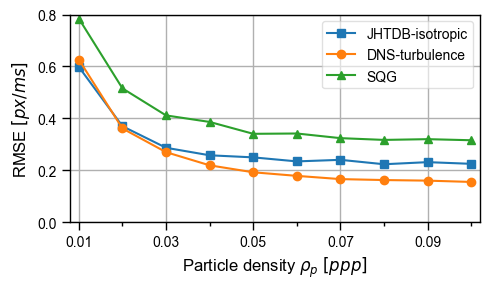

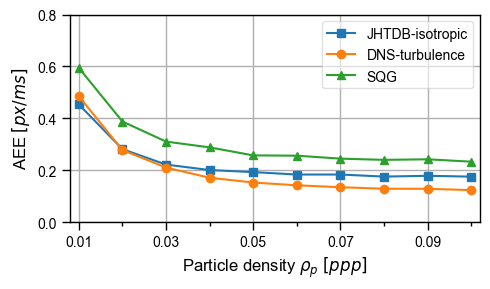

In [7]:
with open("./output/EXP1/3-density-results.json", 'r', encoding='utf-8') as f:
    density_data = json.load(f)
x_vals, y_rmse_list, y_aee_list = extract_data(density_data)

save_density = 1
if save_density == 1:
    rmse_path = "./output/EXP1/3-density-rmse.pdf"
    aee_path = "./output/EXP1/3-density-aee.pdf"
else:
    rmse_path = None
    aee_path = None

use_Chinese = 0
if use_Chinese == 1:
    use_chinese = True
    size = [14, 14, 18]
else:
    use_chinese = False
    size = [10, 10, 12]


def metric_axis_config(y_data_list, tick_step=0.2):
    vals = np.concatenate([np.asarray(y, dtype=float) for y in y_data_list])
    vals = vals[np.isfinite(vals)]
    if vals.size == 0:
        return None, None
    y_max = float(vals.max())
    upper = np.ceil((y_max + 1e-9) / tick_step) * tick_step
    upper = max(tick_step, upper)
    if upper - y_max < 0.05 * tick_step:
        upper += tick_step
    upper = round(float(upper), 2)
    ticks = list(np.round(np.arange(0, upper + 0.5 * tick_step, tick_step), 2))
    return (0, upper), ticks


legend_names_en = flow_names
rmse_ylim, rmse_y_major_ticks = metric_axis_config(y_rmse_list, tick_step=0.2)
aee_ylim, aee_y_major_ticks = metric_axis_config(y_aee_list, tick_step=0.2)

# The experiment samples 0.01 to 0.10 ppp with a 0.01 interval.
density_sample_ticks = list(np.round(np.arange(0.01, 0.1001, 0.01), 2))
x_major_ticks = list(np.round(np.arange(0.01, 0.1001, 0.02), 2))
x_minor_ticks = density_sample_ticks

plot_curvegraph(x_data=x_vals, y_data_list=y_rmse_list, 
    legend_names_en=legend_names_en, legend_names_zh=None, 
    title_en=None, title_zh=None, 
    xlabel_en='Particle density $\\rho_{p}$ $[ppp]$', xlabel_zh='粒子密度 $\\rho_{p}$', 
    ylabel_en="RMSE $[px/ms]$", ylabel_zh="RMSE $[px/ms]$", 
    ticks_size=size[0], legend_size=size[1], label_size=size[2], 
    xlim=(0.008, 0.102), ylim=rmse_ylim, 
    x_major_ticks=x_major_ticks, x_minor_ticks=x_minor_ticks,
    y_major_ticks=rmse_y_major_ticks, y_minor_ticks=None,
    x_log=False, filename=rmse_path, use_chinese=use_chinese)

plot_curvegraph(x_data=x_vals, y_data_list=y_aee_list, 
    legend_names_en=legend_names_en, legend_names_zh=None, 
    title_en=None, title_zh=None, 
    xlabel_en='Particle density $\\rho_{p}$ $[ppp]$', xlabel_zh='粒子密度 $\\rho_{p}$', 
    ylabel_en="AEE $[px/ms]$", ylabel_zh="AEE $[px/ms]$", 
    ticks_size=size[0], legend_size=size[1], label_size=size[2], 
    xlim=(0.008, 0.102), ylim=aee_ylim, 
    x_major_ticks=x_major_ticks, x_minor_ticks=x_minor_ticks,
    y_major_ticks=aee_y_major_ticks, y_minor_ticks=None,
    x_log=False, filename=aee_path, use_chinese=use_chinese)


- noise ratio

In [ ]:
noise_results = {}

for i in tqdm(range(3), desc="flows"):
    flow_func = globals()[f"flow{i}"].evaluate
    cfg_evts = config_events()
    cfg_evts.time_length = 5
    cfg_evts.density = 0.05
    cfg_evts.d = 0.5
    
    event_loader = EventManager(source_type="simulator", path=None, cfg=cfg_evts, flow_func=flow_func)
    evts, (u, v) = event_loader.load()
    u_gt, v_gt = u.cpu().numpy(), v.cpu().numpy()

    single_flow_results = {}

    for j, noise_ratio in enumerate(tqdm(np.arange(0, 0.21, 0.02), desc=f"  Noise ratio", leave=False)):
        rmse_list, aee_list = [], []

        for k in range(10):
            events = evts[(evts[:, 2] > 0) & (evts[:, 2] < 3)]
            noisy_events = add_event_noise(events, 256, 256 , noise_ratio = noise_ratio)
            
            cfg = GaussianFlowConfig()
            res = run_gaussian_flow(events=noisy_events, cfg=cfg, flowgt=None)
            pred_h, pred_w = res.flow[:2]
            rmse, aee = PIVmetric(u_gt, v_gt, pred_h, pred_w, show=False)[:2]

            rmse_list.append(float(rmse))
            aee_list.append(float(aee))

        rmse_mean = np.mean(np.sort(rmse_list)[1:-1])
        aee_mean = np.mean(np.sort(aee_list)[1:-1])

        single_flow_results[f"{noise_ratio:.2f}"] = {
            "rmse": round(rmse_mean, 4),
            "aee": round(aee_mean, 4)
        }

    noise_results[flow_names[i]] = single_flow_results

save_results_to_json(noise_results, "./output/EXP1/4-noise-results.json", indent=1)

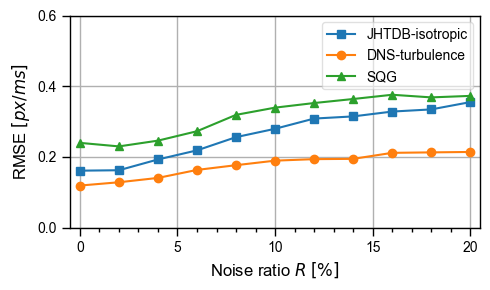

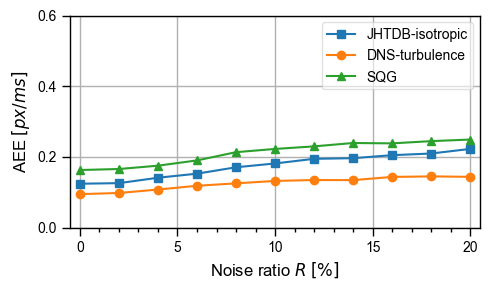

In [8]:
with open("./output/EXP1/4-noise-results.json", 'r', encoding='utf-8') as f:
    noise_data = json.load(f)
x_vals, y_rmse_list, y_aee_list = extract_data(noise_data)

legend_names_en = flow_names
y_major_ticks = [0, 0.2, 0.4, 0.6]

save_noise = 1
if save_noise == 1:
    rmse_path = "./output/EXP1/4-noise-rmse.pdf"
    aee_path = "./output/EXP1/4-noise-aee.pdf"
else:
    rmse_path = None
    aee_path = None

use_Chinese = 0
if use_Chinese ==1:
    use_chinese = True
    size = [14, 14, 18]
else:
    use_chinese = False
    size = [10, 10, 12]
    
x_major_ticks = list(range(0, 21, 5))
x_minor_ticks = list(range(1, 21, 1))

plot_curvegraph(x_data=x_vals*100, y_data_list=y_rmse_list, 
    legend_names_en=legend_names_en, legend_names_zh=None, 
    title_en=None, title_zh=None, 
    xlabel_en="Noise ratio $R$ $[\%]$", xlabel_zh="噪声比例 $R$ $[\%]$", 
    ylabel_en="RMSE $[px/ms]$", ylabel_zh="RMSE $[px/ms]$", 
    ticks_size=size[0], legend_size=size[1], label_size=size[2], 
    xlim=(-0.5, 20.5), ylim=(0, 0.6), 
    x_major_ticks=x_major_ticks, x_minor_ticks=x_minor_ticks,
    y_major_ticks=y_major_ticks, y_minor_ticks=None,
    x_log=False, filename=rmse_path, 
    use_chinese=use_chinese)

plot_curvegraph(x_data=x_vals*100, y_data_list=y_aee_list, 
    legend_names_en=legend_names_en, legend_names_zh=None, 
    title_en=None, title_zh=None, 
    xlabel_en="Noise ratio $R$ $[\%]$", xlabel_zh="噪声比例 $R$ $[\%]$", 
    ylabel_en="AEE $[px/ms]$", ylabel_zh="AEE $[px/ms]$", 
    ticks_size=size[0], legend_size=size[1], label_size=size[2], 
    xlim=(-0.5, 20.5), ylim=(0, 0.6), 
    x_major_ticks=x_major_ticks, x_minor_ticks=x_minor_ticks,
    y_major_ticks=y_major_ticks, y_minor_ticks=None,
    x_log=False, filename=aee_path, 
    use_chinese=use_chinese)

## Divergence top-ratio sweep

This experiment varies the percentage of the largest-divergence responses used by the weak divergence regularizer from 0% to 20% in 1% increments.


In [ ]:
import importlib
import methods.affinegs.gaussian_flow.config as gf_config
import methods.affinegs.gaussian_flow.training as gf_training

# Reload edited gaussian_flow modules so the notebook sees GaussianFlowConfig.div_top_ratio.
importlib.reload(gf_config)
importlib.reload(gf_training)
GaussianFlowConfig = gf_config.GaussianFlowConfig
run_gaussian_flow = gf_training.run_gaussian_flow

div_ratio_sweep_results = {}

# Ratio of largest |div| responses used by the regularizer.
# 0.00 = no divergence regularization; 0.10 = selected default; 0.20 = upper bound of the sensitivity range.
div_top_ratios = np.round(np.arange(0.0, 0.5001, 0.05), 2)
num_repeats_ratio = 5
ratio_base_seed = 20260710


def set_all_seeds(seed_value):
    np.random.seed(seed_value)
    torch.manual_seed(seed_value)
    if torch.cuda.is_available():
        torch.cuda.manual_seed(seed_value)
        torch.cuda.manual_seed_all(seed_value)


for flow_index in tqdm(range(3), desc="Flows"):
    flow_key = f"flow{flow_index}"
    flow_name = flow_names[flow_index]
    div_ratio_sweep_results[flow_name] = {}

    set_all_seeds(ratio_base_seed + flow_index)
    flow_func = globals()[flow_key].evaluate
    cfg_evts = config_events()
    cfg_evts.time_length = 5
    cfg_evts.density = 0.05
    cfg_evts.d = 0.5

    event_loader = EventManager(source_type="simulator", path=None, cfg=cfg_evts, flow_func=flow_func)
    evts, (u, v) = event_loader.load()
    events = evts[(evts[:, 2] > 0) & (evts[:, 2] < 3)]

    u_gt = u.detach().cpu().numpy()
    v_gt = v.detach().cpu().numpy()

    for ratio in tqdm(div_top_ratios, desc=f"  {flow_name} ratios", leave=False):
        rmse_list, aee_list = [], []

        for repeat_index in range(num_repeats_ratio):
            # Paired seed across ratios: only div_top_ratio changes.
            run_seed = ratio_base_seed + flow_index * 100 + repeat_index
            set_all_seeds(run_seed)

            cfg = GaussianFlowConfig(
                w_div=GaussianFlowConfig().w_div,
                div_top_ratio=float(ratio),
                lr_j=0.001,
                verbose=False,
            )
            result = run_gaussian_flow(events=events, cfg=cfg, flowgt=None)
            pred_h, pred_w = result.flow[:2]
            rmse, aee = PIVmetric(u_gt, v_gt, pred_h, pred_w, show=False)[:2]

            rmse_list.append(float(rmse))
            aee_list.append(float(aee))

            if torch.cuda.is_available():
                torch.cuda.empty_cache()

        div_ratio_sweep_results[flow_name][f"{ratio:.2f}"] = {
            "rmse": round(float(np.mean(rmse_list)), 4),
            "aee": round(float(np.mean(aee_list)), 4),
            "std_rmse": round(float(np.std(rmse_list)), 4),
            "std_aee": round(float(np.std(aee_list)), 4),
            "num_repeats": int(num_repeats_ratio),
        }

save_results_to_json(div_ratio_sweep_results, "./output/EXP1/5-div-top-ratio-sweep-results.json", indent=1)

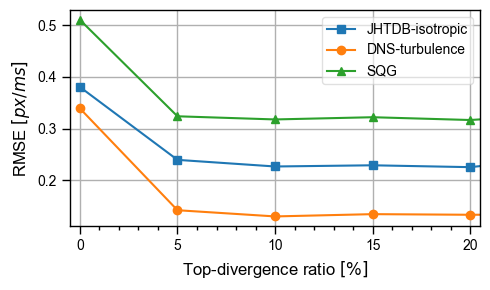

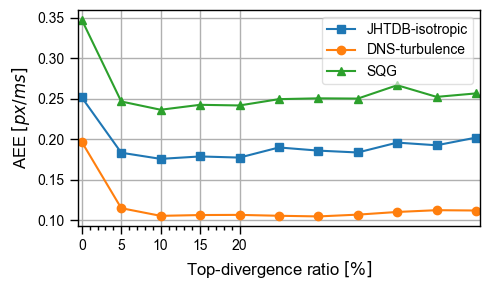

In [12]:
with open("./output/EXP1/5-div-top-ratio-sweep-results.json", "r", encoding="utf-8") as f:
    div_ratio_sweep_data = json.load(f)


def extract_div_ratio_sweep(data, metric):
    x_vals = None
    y_list = []
    for flow_name in flow_names:
        ratios = np.array(sorted([float(k) for k in data[flow_name].keys()]), dtype=float)
        values = np.array([data[flow_name][f"{r:.2f}"][metric] for r in ratios], dtype=float)
        if x_vals is None:
            x_vals = ratios
        y_list.append(values)
    return x_vals, y_list


x_vals, y_rmse_list = extract_div_ratio_sweep(div_ratio_sweep_data, "rmse")
_, y_aee_list = extract_div_ratio_sweep(div_ratio_sweep_data, "aee")

legend_names_en = flow_names
save_div_ratio = 1
if save_div_ratio == 1:
    rmse_path = "./output/EXP1/5-div-top-ratio-sweep-rmse.pdf"
    aee_path = "./output/EXP1/5-div-top-ratio-sweep-aee.pdf"
else:
    rmse_path = None
    aee_path = None

use_Chinese = 0
if use_Chinese == 1:
    use_chinese = True
    size = [14, 14, 18]
else:
    use_chinese = False
    size = [10, 10, 12]

x_major_ticks = list(range(0, 21, 5))
x_minor_ticks = list(range(1, 21, 1))

plot_curvegraph(
    x_data=x_vals * 100,
    y_data_list=y_rmse_list,
    legend_names_en=legend_names_en,
    legend_names_zh=None,
    title_en=None,
    title_zh=None,
    xlabel_en="Top-divergence ratio $[\\%]$",
    xlabel_zh="最大散度比例 $[\\%]$",
    ylabel_en="RMSE $[px/ms]$",
    ylabel_zh="RMSE $[px/ms]$",
    ticks_size=size[0],
    legend_size=size[1],
    label_size=size[2],
    xlim=(-0.5, 20.5),
    ylim=None,
    x_major_ticks=x_major_ticks,
    x_minor_ticks=x_minor_ticks,
    y_major_ticks=None,
    y_minor_ticks=None,
    x_log=False,
    filename=rmse_path,
    use_chinese=use_chinese,
)

plot_curvegraph(
    x_data=x_vals * 100,
    y_data_list=y_aee_list,
    legend_names_en=legend_names_en,
    legend_names_zh=None,
    title_en=None,
    title_zh=None,
    xlabel_en="Top-divergence ratio $[\\%]$",
    xlabel_zh="最大散度比例 $[\\%]$",
    ylabel_en="AEE $[px/ms]$",
    ylabel_zh="AEE $[px/ms]$",
    ticks_size=size[0],
    legend_size=size[1],
    label_size=size[2],
    xlim=(-0.5, 50.5),
    ylim=None,
    x_major_ticks=x_major_ticks,
    x_minor_ticks=x_minor_ticks,
    y_major_ticks=None,
    y_minor_ticks=None,
    x_log=False,
    filename=aee_path,
    use_chinese=use_chinese,
)
